In [1]:
import argparse
import math
import os
import pandas as pd
from dataclasses import dataclass, field
from math import pi
from typing import Any, Generator, List, Optional

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import rosbag2_py
import scipy
from builtin_interfaces.msg import Time
from control_msgs.msg import DynamicJointState
from geometry_msgs.msg import PoseStamped, Vector3, Vector3Stamped, Pose
from numpy.typing import NDArray
from rclpy.serialization import deserialize_message
from rosidl_runtime_py.utilities import get_message
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.spatial.transform import Rotation as R
from sensor_msgs.msg import Imu
from std_msgs.msg import Header, String

from motor_msgs.msg import MotorCurrents
import sys
# import ros2_numpy as rnp
import rosbag2_py._storage as storage
from collections import defaultdict

from bag_utils import get_metadata, get_reader

import tf2_ros
import tf2_geometry_msgs
from geometry_msgs.msg import TwistStamped
from tf2_msgs.msg import TFMessage
import rclpy
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial.transform import Rotation as R
import PyKDL

from tf2_ros import TransformStamped
from control_msgs.msg import DynamicJointState

from motor_msgs.msg import MotorCurrents

from pandas import DataFrame, Series
from sensor_msgs.msg import Imu

In [5]:
bag_file = (
    "../../logging/2025_2_16_rosbags/2025_2_16__17_14_4760RPM_vinyl_linear_skid.bag"
)
meta_data = get_metadata(input_bag=bag_file)
reader = get_reader(input_bag=bag_file)
print(meta_data)

# [print(k.topic_metadata.name) for k in meta_data.topics_with_message_count]


Files:             2025_2_16__17_14_4760RPM_vinyl_linear_skid.bag_0.mcap
Bag size:          7.1 MiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          23.625060802s
Start:             Feb 16 2025 22:14:47.817216576 (1739744087.817216576)
End:               Feb 16 2025 22:15:11.442277378 (1739744111.442277378)
Messages:          45851
Topic information: Topic: /diagnostics | Type: diagnostic_msgs/msg/DiagnosticArray | Count: 23 | Serialization Format: cdr
                   Topic: /dynamic_joint_states | Type: control_msgs/msg/DynamicJointState | Count: 572 | Serialization Format: cdr
                   Topic: /events/write_split | Type: rosbag2_interfaces/msg/WriteSplitEvent | Count: 0 | Serialization Format: cdr
                   Topic: /joint_state_broadcaster/transition_event | Type: lifecycle_msgs/msg/TransitionEvent | Count: 0 | Serialization Format: cdr
                   Topic: /joint_states | Type: sensor_msgs/msg/JointState | Count: 572 | Serialization Forma

In [ ]:
# Create a dict of lists with keys matching the the topic names
msgs = {k.topic_metadata.name: [] for k in meta_data.topics_with_message_count}

# Populate lists with corresponding messages.
for topic, msg, timestamp in reader:
    # print(topic)
    # msgs.append(msg)
    msgs[topic].append(msg)


In [ ]:
# We get a list of tf2_msgs.msg.TFMessage objects. Not transforms!
print(len(msgs["/tf_static"]))
print(msgs["/tf_static"])

2
[tf2_msgs.msg.TFMessage(transforms=[geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=1739743955, nanosec=879674800), frame_id='base_link'), child_frame_id='body_assembly', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=0.0, y=0.0, z=0.0), rotation=geometry_msgs.msg.Quaternion(x=0.0, y=0.0, z=0.0, w=1.0))), geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=1739743955, nanosec=879674800), frame_id='bl_wheel'), child_frame_id='bl_tire', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=4.85722573273506e-17, y=5.551115123125783e-17, z=0.13379450000000004), rotation=geometry_msgs.msg.Quaternion(x=-7.216449660051615e-16, y=3.885780586188474e-16, z=-2.775557561553138e-16, w=1.0))), geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=1739743955, nanosec=879674800), frame_id='br_wheel'), 

In [8]:
# import numpy as np
# import matplotlib.pyplot as plt

# def extract_tf_data(tf_static_msgs):
#     """ Extract frame names and positions from /tf_static messages. """
#     transforms = {}

#     for msg in tf_static_msgs:  # Only process TFMessage objects
#         for transform in msg.transforms:
#             parent = transform.header.frame_id
#             child = transform.child_frame_id
#             translation = transform.transform.translation

#             # Store transform data
#             transforms[child] = {
#                 "parent": parent,
#                 "x": translation.x,
#                 "y": translation.y
#             }

#     return transforms

# def plot_tf_2d(transforms):
#     """ Plot TF tree in 2D (XY plane) using Matplotlib. """
#     fig, ax = plt.subplots(figsize=(8, 6))

#     for child, tf in transforms.items():
#         parent = tf["parent"]
#         x, y = tf["x"], tf["y"]

#         # Get parent position (default to origin if missing)
#         try:
#             parent_x, parent_y = transforms.get(parent, {"x": 0, "y": 0}).values()
#         except Exception as e:
#             print(e)

#         # Plot frame position
#         ax.scatter(x, y, label=child, s=100)

#         # Draw a line from parent to child
#         ax.plot([parent_x, x], [parent_y, y], 'k--')

#         # Label child frame
#         ax.text(x, y, child, fontsize=10, ha="right", bbox=dict(facecolor='white', alpha=0.7))

#     ax.set_xlabel("X Position (m)")
#     ax.set_ylabel("Y Position (m)")
#     ax.set_title("2D TF Static Transform Tree")
#     ax.grid()
#     plt.legend()
#     plt.show()

# %matplotlib widget
# # Extract and plot all transforms
# tfs = msgs['/tf_static']['data']  # List of TFMessage objects
# transforms = extract_tf_data(tfs)  # Now correctly processes TFMessage
# plot_tf_2d(transforms)



# Apply Transform to Twist Message
This is a little more complicated than for a pose since we're working with XX manifolds. Sophus would do this for us but that is C++ only. It seems to be the case that tf2_kdl has some methods for us to use. This requires us to convert our TwistStamped and PoseStamped into KDL representations which means we have to juggle any frame_id's or time stamps. Ought we to do this 

* Transform a TwistStamped
* Transform a PoseStamped
* Transform a DF of TwistStamped data
* Transform a DF of PoseStamped data

For PoseStamped data we can use the existing geometry_msgs functions for this.

https://github.com/ros2/geometry2/blob/4ec4f9684d03a903da951ab6d4d08cbc87de49ee/tf2_kdl/src/tf2_kdl/tf2_kdl.py#L146

For the Twist data we can use `tf2_kdl.do_transform_twist`. This has a bug! For some reason they try to set the header on a KDL frame object? It's a simple thing to implement ourselves though.

In [9]:
from tf2_kdl import transform_to_kdl


# http://docs.ros.org/en/diamondback/api/kdl/html/python/geometric_primitives.html?highlight=twist#PyKDL.Twist
def do_transform_twist(twist, transform):
    """
    Apply a transform in the form of a geometry_msgs message to a PyKDL Twist.

    :param twist: The PyKDL twist to transform.
    :type twist: PyKDL.Twist
    :param transform: The transform to apply.
    :type transform: geometry_msgs.msg.TransformStamped
    :return: The transformed PyKDL twist.
    :rtype: PyKDL.Twist
    """
    res: PyKDL.Frame = transform_to_kdl(transform) * twist
    # res.header = transform.header
    return res

def transform_twist_dataframe(df, transform):
    """Transforms a DataFrame of twists (linear xyz + angular rpy) into another frame using PyKDL.
    :param df: Pandas DataFrame with columns ['vx', 'vy', 'vz', 'wx', 'wy', 'wz'] representing a twist (linear and angular velocity).
    :param transform: Transform from the original frame to the target frame (geometry_msgs.msg.TransformStamped).
    :return: New DataFrame with transformed twists.
    """
    transformed_data = []

    # For each Twist msg, make a new KDL Twist version of it.
    for _, row in df.iterrows():
        # Create PyKDL Twist (linear velocity, angular velocity)
        twist = PyKDL.Twist(
            PyKDL.Vector(row["vx"], row["vy"], row["vz"]),  # Linear velocity
            PyKDL.Vector(row["wx"], row["wy"], row["wz"]),  # Angular velocity
        )

        transformed_twist = do_transform_twist(twist, transform)

        # Store transformed values
        transformed_data.append(
            [
                transformed_twist.vel[0],
                transformed_twist.vel[1],
                transformed_twist.vel[2],
                transformed_twist.rot[0],
                transformed_twist.rot[1],
                transformed_twist.rot[2],
            ]
        )

    # Create a new DataFrame with the transformed data
    new_df = pd.DataFrame(
        transformed_data, columns=["vx", "vy", "vz", "wx", "wy", "wz"], index=df.index
    )
    return new_df


def transform_pose_dataframe(df, transform):
    """Same as for twist but without adjoint transform."""
    ...


In [10]:
from typing import List, Union, Any, Optional
import pandas as pd
from pandas import DataFrame
import array

def ros_message_to_df(messages: Union[Any, List[Any]], fields: Optional[List[str]] = None) -> DataFrame:
    """
    Convert a ROS 2 message (or a list of messages) into a Pandas DataFrame.
    
    - Extracts all numeric fields from the message.
    - Recursively flattens nested structures.
    - Uses timestamp from 'header.stamp' as index if available.
    - Allows filtering specific fields using dot notation (e.g., 'pose.position.x').

    :param messages: A single ROS message or a list of ROS messages.
    :param fields: A list of field names to keep. If None, keeps all fields.
    :return: Pandas DataFrame with extracted fields.
    """
    if not isinstance(messages, list):
        messages = [messages]  # Convert single message to list

    # Extract data
    data = []
    indices = []

    for msg in messages:
        if hasattr(msg, "joint_names") and hasattr(msg, "interface_values"):
            msg_dict = flatten_dynamic_joint_state(msg)
        else:
            msg_dict = flatten_ros_message(msg)
        
        msg_dict = {k: v for k, v in msg_dict.items() if not k.endswith("check_fields")}

        timestamp = None
        if hasattr(msg, "header") and hasattr(msg.header, "stamp"):
            timestamp = msg.header.stamp.sec + msg.header.stamp.nanosec / 1e9
            indices.append(timestamp)

        data.append(msg_dict)

    # Create DataFrame
    df = pd.DataFrame(data)

    if df.empty:
        raise ValueError("No valid data extracted from messages.")

    # Convert requested dot notation fields into the flattened keys
    if fields is not None:
        # flattened_keys = [field.replace(".", "_") for field in fields]
        # flattened_keys = fields
        
        # Check for missing fields
        missing_fields = [col for col in fields if col not in df.columns]
        if missing_fields:
            raise KeyError(f"Requested fields {missing_fields} not found. Available fields: {list(df.columns)}")

        df = df[fields]

        # Rename back from underscores to dot notation for clarity
        df.columns = fields

    # Set index as timestamp if available
    if indices:
        df.index = pd.to_datetime(indices, unit='s')
        df.index.name = "timestamp"

    return df


def flatten_ros_message(msg: Any, prefix: str = "") -> dict:
    """
    Recursively flatten a ROS message into a dictionary, using dot notation
    while removing private underscores.
    
    - Keeps string fields (e.g., child_frame_id) as-is.
    - Uses dot notation only for nested ROS messages.

    :param msg: ROS message instance.
    :param prefix: Prefix for nested field names.
    :return: Dictionary of flattened fields.
    """
    result = {}

    # If it's a simple data type (int, float, str, bool), return as-is
    if isinstance(msg, (int, float, bool, str)):
        return {prefix.rstrip("."): msg}  # Keep string fields without dot notation

    # If it's a ROS message (has __slots__), recursively extract attributes
    if hasattr(msg, "__slots__"):
        for attr in msg.__slots__:
            value = getattr(msg, attr)

            # Keep child_frame_id as-is (do not flatten)
            if isinstance(value, str):
                # if value == 'check_fields':
                #     continue
                result[f"{prefix}{attr}"] = value
                continue

            # Remove leading underscores from attribute names
            clean_attr = attr.lstrip("_")
            key = f"{prefix}{clean_attr}."  # Use dot notation
                        # Expand float arrays into separate indexed columns

            # Handle float64[] arrays and array.array
            if isinstance(value, (list, array.array)) and all(isinstance(i, (int, float)) for i in value):
                for i, v in enumerate(value):
                    result[f"{key}{i}"] = v  # Example: "data_0", "data_1"
            else:
                result.update(flatten_ros_message(value, key))

    return result

def flatten_dynamic_joint_state(msg: Any) -> dict:
    """
    Flatten a `DynamicJointState` message into a dictionary using dot notation.

    - Expands `joint_names` into a structured format.
    - Extracts `interface_values` for each joint.
    - Uses dot notation (e.g., `joint.br_wheel_joint.velocity` instead of underscores).

    :param msg: The `DynamicJointState` message.
    :return: Dictionary of expanded fields.
    """
    result = {}

    if not hasattr(msg, "joint_names") or not hasattr(msg, "interface_values"):
        return result

    joint_names = msg.joint_names  # List of joint names
    interface_values = msg.interface_values  # List of InterfaceValue messages

    if len(joint_names) != len(interface_values):
        raise ValueError(f"Mismatch: {len(joint_names)} joint names but {len(interface_values)} interface value lists.")

    for joint_idx, joint_name in enumerate(joint_names):
        joint_interfaces = interface_values[joint_idx]  # Get the corresponding interface values

        if hasattr(joint_interfaces, "values") and hasattr(joint_interfaces, "interface_names"):
            for i, interface_name in enumerate(joint_interfaces.interface_names):
                key = f"joint.{joint_name}.{interface_name}"  # Use dot notation
                result[key] = joint_interfaces.values[i] if i < len(joint_interfaces.values) else None

    return result



In [11]:
print(msgs['/dynamic_joint_states'][100])

control_msgs.msg.DynamicJointState(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=1739744092, nanosec=509289989), frame_id=''), joint_names=['fr_wheel_joint', 'br_wheel_joint', 'fl_wheel_joint', 'bl_wheel_joint'], interface_values=[control_msgs.msg.InterfaceValue(interface_names=['position', 'velocity', 'encoder_count', 'current'], values=[-14.322353669753085, 0.0, -14771.0, 0.0]), control_msgs.msg.InterfaceValue(interface_names=['position', 'velocity', 'encoder_count', 'current'], values=[-14.633603790123455, 0.0, -15092.0, 0.0]), control_msgs.msg.InterfaceValue(interface_names=['position', 'velocity', 'encoder_count', 'current'], values=[-16.123919787037035, 0.0, -16629.0, 0.0]), control_msgs.msg.InterfaceValue(interface_names=['position', 'velocity', 'encoder_count', 'current'], values=[-15.487844774691357, 0.0, -15973.0, 0.0])])


<Axes: title={'center': 'foo'}, xlabel='timestamp'>

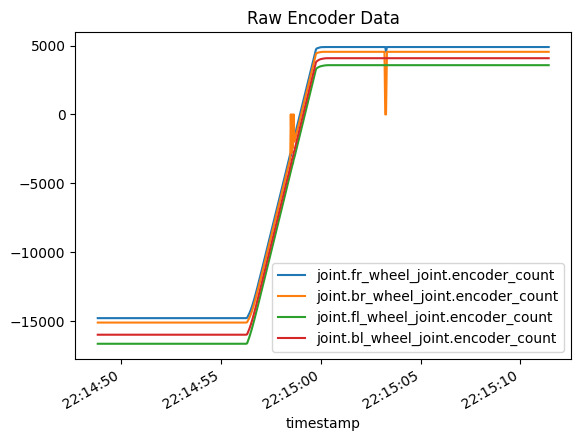

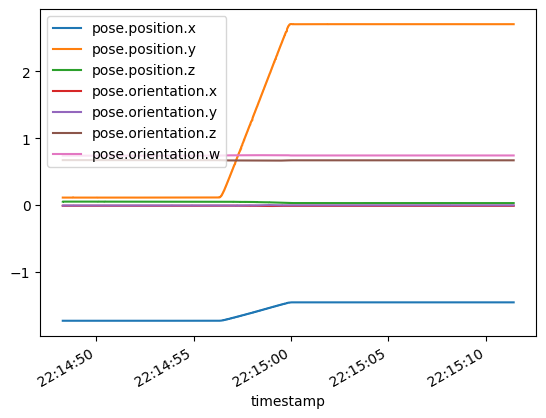

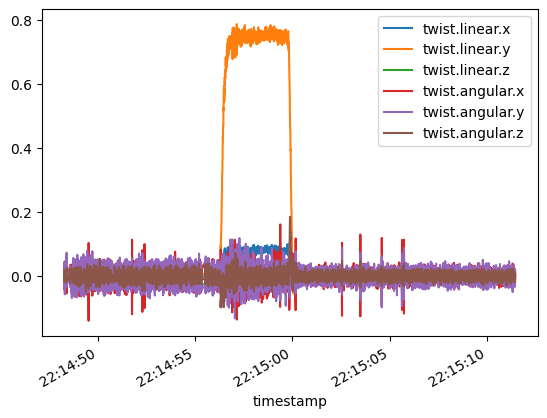

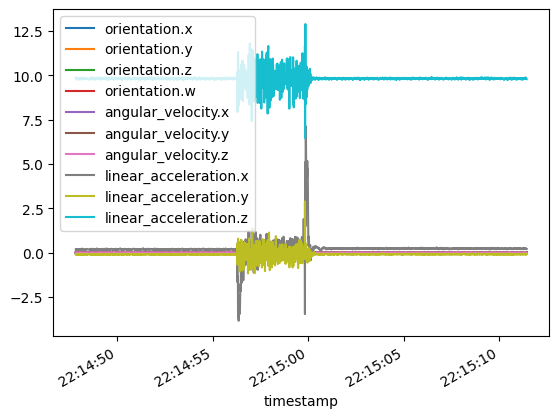

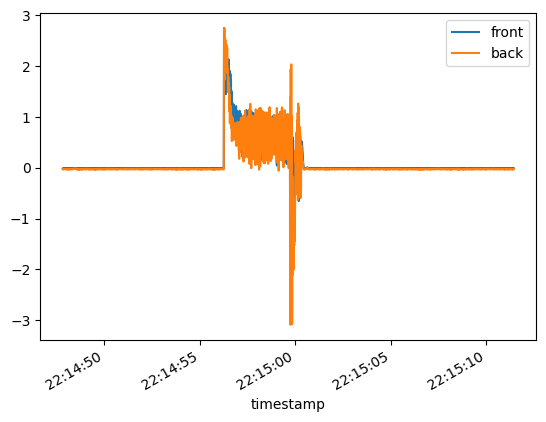

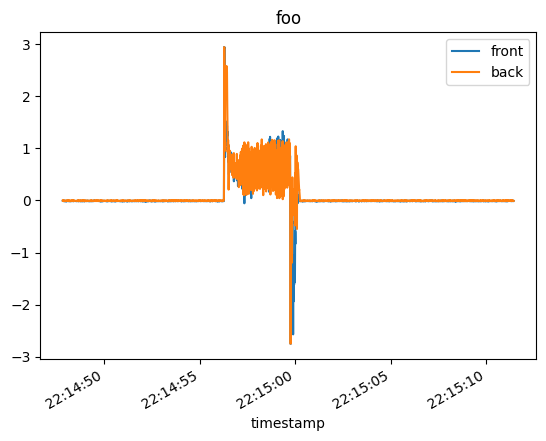

In [12]:
tf_static_msgs: list[TransformStamped] = msgs["/tf_static"]
tf_msgs: List[TransformStamped] = msgs["/tf"]

wheel_data_msgs: List[DynamicJointState] = msgs["/dynamic_joint_states"]
wheel_data = ros_message_to_df(wheel_data_msgs)
wheel_data.plot( title="Raw Encoder Data",
    y=[
        "joint.fr_wheel_joint.encoder_count",
        "joint.br_wheel_joint.encoder_count",
        "joint.fl_wheel_joint.encoder_count",
        "joint.bl_wheel_joint.encoder_count"

        # "joint.fr_wheel_joint.position",
        # "joint.br_wheel_joint.position",
        # "joint.fl_wheel_joint.position",
        # "joint.bl_wheel_joint.position",

        # "joint.fr_wheel_joint.current",
        # "joint.br_wheel_joint.current",
        # "joint.fl_wheel_joint.current",
        # "joint.bl_wheel_joint.current",

        # "joint.fr_wheel_joint.velocity",
        # "joint.br_wheel_joint.velocity",
        # "joint.fl_wheel_joint.velocity",
        # "joint.bl_wheel_joint.velocity",
    ]
)

vicon_pose_msgs: list[PoseStamped] = msgs["/vrpn_mocap/rb1/pose"]
vicon_poses = ros_message_to_df(vicon_pose_msgs)
vicon_poses.plot(
    y=[
        "pose.position.x",
        "pose.position.y",
        "pose.position.z",
        "pose.orientation.x",
        "pose.orientation.y",
        "pose.orientation.z",
        "pose.orientation.w",
    ]
)

vicon_twist_msgs: list[TwistStamped] = msgs["/vrpn_mocap/rb1/twist"]
vicon_twists = ros_message_to_df(vicon_twist_msgs)
vicon_twists.plot(
    y=[
        "twist.linear.x",
        "twist.linear.y",
        "twist.linear.z",
        "twist.angular.x",
        "twist.angular.y",
        "twist.angular.z",
    ]
)


# IMU Data.
imu_msgs: list[Imu] = msgs["/pico_imu"]
imu = ros_message_to_df(imu_msgs)
imu.attrs = {"name": "imu_raw"}
imu.plot(
    y=[
        "orientation.x",
        "orientation.y",
        "orientation.z",
        "orientation.w",
        "angular_velocity.x",
        "angular_velocity.y",
        "angular_velocity.z",
        "linear_acceleration.x",
        "linear_acceleration.y",
        "linear_acceleration.z",
    ]
)


# Left Motor Currents.
left_current_msgs: List[MotorCurrents] = msgs["/left_motor_currents"]
left_currents = ros_message_to_df(left_current_msgs)
left_currents.rename(columns={"data.0": "front", "data.1": "back"}, inplace=True)
left_currents.back *= -1  # I thought it was just the back motors?
left_currents.front *= -1
left_currents.plot(y=["front", "back"])

# Right Motor Currents.
right_current_msgs: List[MotorCurrents] = msgs["/right_motor_currents"]
right_currents = ros_message_to_df(right_current_msgs)
right_currents.rename(columns={"data.0": "front", "data.1": "back"}, inplace=True)
# right_currents.back *= -1
right_currents.plot(y=["front", "back"], title="foo")




In [13]:
wheel_data.describe()

,joint.fr_wheel_joint.position,joint.fr_wheel_joint.velocity,joint.fr_wheel_joint.encoder_count,joint.fr_wheel_joint.current,joint.br_wheel_joint.position,joint.br_wheel_joint.velocity,joint.br_wheel_joint.encoder_count,joint.br_wheel_joint.current,joint.fl_wheel_joint.position,joint.fl_wheel_joint.velocity,joint.fl_wheel_joint.encoder_count,joint.fl_wheel_joint.current,joint.bl_wheel_joint.position,joint.bl_wheel_joint.velocity,joint.bl_wheel_joint.encoder_count,joint.bl_wheel_joint.current
count,572.000000,572.000000,572.000000,572.000000,572.000000,5.720000e+02,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000
mean,-3.395290,49.346154,-3501.646853,1.949301,-3.721593,1.234270e+07,-3838.171329,1.961538,-4.874616,8.965035,-5027.312937,0.837413,-4.333231,8.903846,-4468.968531,0.828671
std,8.925227,973.773156,9204.809352,5.706716,8.908032,1.472089e+08,9187.075147,6.666585,9.154490,20.415530,9441.253228,2.786595,9.091710,20.290953,9376.507223,2.756686
min,-14.322354,0.000000,-14771.000000,-59.000000,-14.633604,0.000000e+00,-15092.000000,-79.000000,-16.123920,0.000000,-16629.000000,-9.000000,-15.487845,0.000000,-15973.000000,-9.000000
25%,-14.322354,0.000000,-14771.000000,0.000000,-14.633604,0.000000e+00,-15092.000000,0.000000,-16.123920,0.000000,-16629.000000,0.000000,-15.487845,0.000000,-15973.000000,0.000000
50%,4.390469,0.000000,4528.000000,0.000000,3.748576,0.000000e+00,3866.000000,0.000000,3.084382,0.000000,3181.000000,0.000000,3.572104,0.000000,3684.000000,0.000000
75%,4.740504,0.000000,4889.000000,0.000000,4.404044,0.000000e+00,4542.000000,0.000000,3.464476,0.000000,3573.000000,0.000000,3.955107,0.000000,4079.000000,0.000000
max,4.740504,23293.000000,4889.000000,32.000000,4.404044,1.765005e+09,4542.000000,44.000000,3.465445,58.000000,3574.000000,24.000000,3.955107,58.000000,4079.000000,27.000000


In [14]:
# Transform the vicon Twist data into the robot frame
tf_static_msgs = msgs["/tf_static"]

# Make a TF buffer and populate with static xforms.
tf_buffer = tf2_ros.Buffer()
for tf_msg in tf_static_msgs:
    for transform in tf_msg.transforms:
        # print(transform)
        tf_buffer.set_transform(transform, "default_authority")

# First make a transform from the robot Pose in vicon
# vicon->base_link
vicon_pose_msgs: list[PoseStamped] = msgs["/vrpn_mocap/rb1/pose"]
vicon_poses = ros_message_to_df(vicon_pose_msgs)

vicon_to_base_link = 

print(tf_buffer.all_frames_as_yaml())



SyntaxError: invalid syntax (2802310264.py, line 16)

In [ ]:

def transform_twist_dataframe(df, transform):
    """
    Transforms a DataFrame of twists (linear xyz + angular rpy) into another frame using PyKDL.

    :param df: Pandas DataFrame with columns ['vx', 'vy', 'vz', 'wx', 'wy', 'wz']
               representing a twist (linear and angular velocity).
    :param transform: Transform from the original frame to the target frame (geometry_msgs.msg.TransformStamped).
    :return: New DataFrame with transformed twists.
    """
    transformed_data = []

    # For each Twist msg, make a new KDL Twist version of it.
    for _, row in df.iterrows():
        # Create PyKDL Twist (linear velocity, angular velocity)
        twist = PyKDL.Twist(
            PyKDL.Vector(row['vx'], row['vy'], row['vz']),  # Linear velocity
            PyKDL.Vector(row['wx'], row['wy'], row['wz'])   # Angular velocity
        )

        transformed_twist = do_transform_twist(twist, transform)

        # Store transformed values
        transformed_data.append([
            transformed_twist.vel[0], transformed_twist.vel[1], transformed_twist.vel[2],
            transformed_twist.rot[0], transformed_twist.rot[1], transformed_twist.rot[2]
        ])

    # Create a new DataFrame with the transformed data
    new_df = pd.DataFrame(transformed_data, columns=['vx', 'vy', 'vz', 'wx', 'wy', 'wz'], index=df.index)
    return new_df


In [ ]:
from geometry_msgs.msg import TransformStamped

def pose_to_transform(pose_msg: PoseStamped) -> TransformStamped:
    """
    Convert a PoseStamped message into a TransformStamped message (vicon -> base_link).
    
    :param pose_msg: PoseStamped message representing the robot pose in the Vicon frame.
    :return: TransformStamped message to transform from Vicon frame to the base_link frame.
    """
    transform = TransformStamped()
    transform.header = pose_msg.header
    transform.child_frame_id = "base_link"
    transform.header.frame_id = "vicon"

    # Set translation
    transform.transform.translation.x = pose_msg.pose.position.x
    transform.transform.translation.y = pose_msg.pose.position.y
    transform.transform.translation.z = pose_msg.pose.position.z

    # Set rotation (inverting the orientation for vicon -> base_link)
    q = pose_msg.pose.orientation
    transform.transform.rotation.x = -q.x
    transform.transform.rotation.y = -q.y
    transform.transform.rotation.z = -q.z
    transform.transform.rotation.w = q.w

    return transform



vicon_pose_msgs: list[PoseStamped] = msgs["/vrpn_mocap/rb1/pose"]
vicon_poses = ros_message_to_df(vicon_pose_msgs)

vicon_twist_msgs: list[TwistStamped] = msgs["/vrpn_mocap/rb1/twist"]
vicon_twists = ros_message_to_df(vicon_twist_msgs)


transformed_twists = []

# Process each twist using its corresponding pose
# Will these line up?
for pose_msg, twist_msg in zip(vicon_pose_msgs, vicon_twist_msgs):
    vicon_to_base_link = pose_to_transform(pose_msg)  # Generate transform for this pose
    
    twist = PyKDL.Twist(
        PyKDL.Vector(row['vx'], row['vy'], row['vz']),  # Linear velocity
        PyKDL.Vector(row['wx'], row['wy'], row['wz'])   # Angular velocity
    )
    transformed_twist = do_transform_twist(twist_msg.twist, vicon_to_base_link)

    transformed_twist_stamped = TwistStamped()
    transformed_twist_stamped.header = twist_msg.header  # Preserve original timestamp
    transformed_twist_stamped.twist = transformed_twist
    transformed_twists.append(transformed_twist_stamped)

# Convert transformed twists to a DataFrame
transformed_twist_df = ros_message_to_df(transformed_twists)
print(transformed_twist_df)


NameError: name 'row' is not defined

In [ ]:

import pandas as pd
import PyKDL
from geometry_msgs.msg import TransformStamped
from scipy.spatial.transform import Rotation as R

def pose_to_transform(pose_row) -> TransformStamped:
    """
    Convert a pose DataFrame row into a TransformStamped object.
    
    :param pose_row: A row from the pose DataFrame containing position & orientation.
    :return: TransformStamped object to transform from Vicon frame to base_link.
    """
    transform = TransformStamped()
    transform.header.stamp.sec = int(pose_row.name.timestamp())
    transform.header.stamp.nanosec = int((pose_row.name.timestamp() % 1) * 1e9)
    transform.child_frame_id = "base_link"
    transform.header.frame_id = "vicon"

    # Set translation
    transform.transform.translation.x = pose_row["pose.position.x"]
    transform.transform.translation.y = pose_row["pose.position.y"]
    transform.transform.translation.z = pose_row["pose.position.z"]

    # Set rotation (invert the quaternion for vicon -> base_link)
    q = R.from_quat([pose_row["pose.orientation.x"], 
                     pose_row["pose.orientation.y"], 
                     pose_row["pose.orientation.z"], 
                     pose_row["pose.orientation.w"]]).inv()

    transform.transform.rotation.x, transform.transform.rotation.y, \
        transform.transform.rotation.z, transform.transform.rotation.w = q.as_quat()

    return transform

# Load pose & twist data
vicon_pose_msgs: list[PoseStamped] = msgs["/vrpn_mocap/rb1/pose"]
vicon_poses = ros_message_to_df(vicon_pose_msgs)

vicon_twist_msgs: list[TwistStamped] = msgs["/vrpn_mocap/rb1/twist"]
vicon_twists = ros_message_to_df(vicon_twist_msgs)

# Interpolate poses at twist timestamps
interpolated_poses = vicon_poses.reindex(vicon_twists.index, method='nearest')

transformed_twists = []

# Process each twist using the interpolated pose
for twist_time, twist_row in vicon_twists.iterrows():
    interpolated_pose = interpolated_poses.loc[twist_time]
    vicon_to_base_link = pose_to_transform(interpolated_pose)  # Get interpolated transform

    twist = PyKDL.Twist(
        PyKDL.Vector(twist_row['twist.linear.x'], twist_row['twist.linear.y'], twist_row['twist.linear.z']),  # Linear velocity
        PyKDL.Vector(twist_row['twist.angular.x'], twist_row['twist.angular.y'], twist_row['twist.angular.z'])  # Angular velocity
    )
    
    transformed_twist = do_transform_twist(twist, vicon_to_base_link)

    transformed_twist_stamped = TwistStamped()
    transformed_twist_stamped.header.stamp.sec = int(twist_time.timestamp())
    transformed_twist_stamped.header.stamp.nanosec = int((twist_time.timestamp() % 1) * 1e9)
    transformed_twist_stamped.twist.linear.x = transformed_twist.vel[0]
    transformed_twist_stamped.twist.linear.y = transformed_twist.vel[1]
    transformed_twist_stamped.twist.linear.z = transformed_twist.vel[2]
    transformed_twist_stamped.twist.angular.x = transformed_twist.rot[0]
    transformed_twist_stamped.twist.angular.y = transformed_twist.rot[1]
    transformed_twist_stamped.twist.angular.z = transformed_twist.rot[2]

    transformed_twists.append(transformed_twist_stamped)

# Convert transformed twists to a DataFrame
transformed_twist_df = ros_message_to_df(transformed_twists)
print(transformed_twist_df)


                               header.stamp.sec  header.stamp.nanosec  \
timestamp                                                               
2025-02-16 22:14:48.284708023        1739744088             284708023   
2025-02-16 22:14:48.284847021        1739744088             284847021   
2025-02-16 22:14:48.284955025        1739744088             284955024   
2025-02-16 22:14:48.285063982        1739744088             285063982   
2025-02-16 22:14:48.294745922        1739744088             294745922   
...                                         ...                   ...   
2025-02-16 22:15:11.414700985        1739744111             414700984   
2025-02-16 22:15:11.414834976        1739744111             414834976   
2025-02-16 22:15:11.424704075        1739744111             424704074   
2025-02-16 22:15:11.424839973        1739744111             424839973   
2025-02-16 22:15:11.434724092        1739744111             434724092   

                              header._frame_id  tw

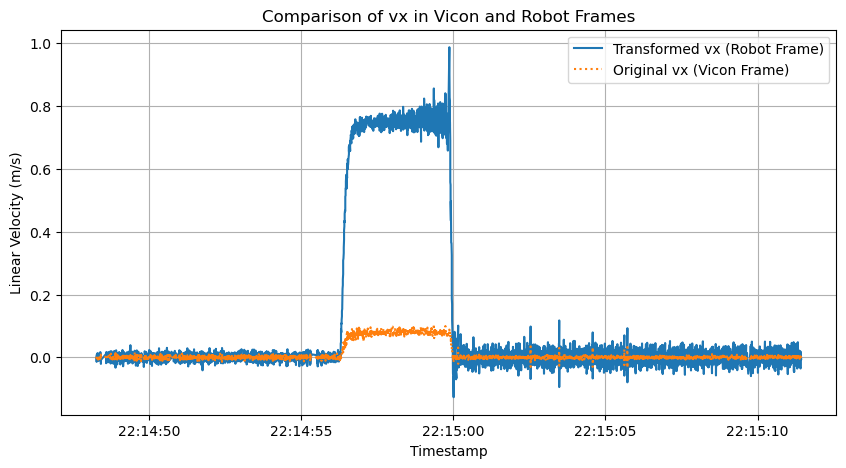

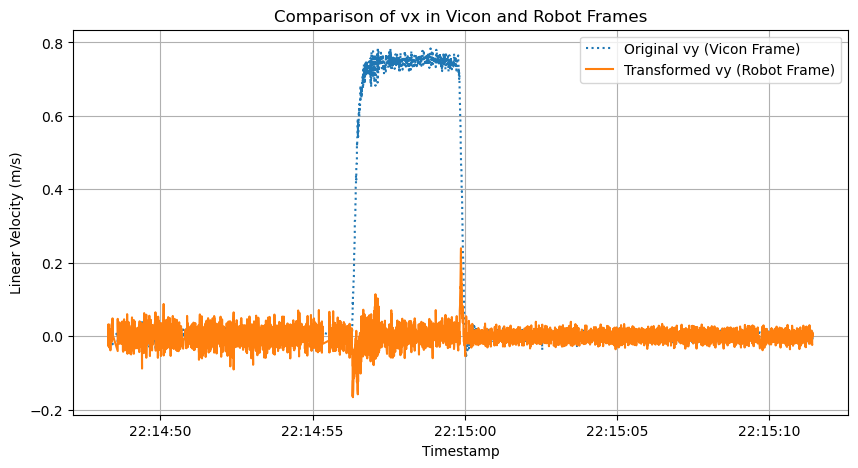

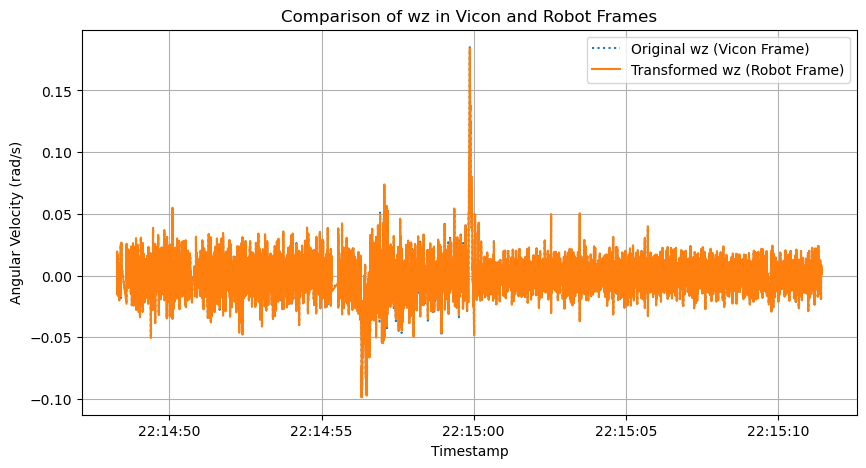

In [ ]:
import matplotlib.pyplot as plt

# Plot linear velocities before and after transformation
plt.figure(figsize=(10, 5))
plt.plot(vicon_twists.index, transformed_twist_df["twist.linear.x"], label="Transformed vx (Robot Frame)", linestyle="-")
plt.plot(vicon_twists.index, vicon_twists["twist.linear.x"], label="Original vx (Vicon Frame)", linestyle="dotted")
plt.xlabel("Timestamp")
plt.ylabel("Linear Velocity (m/s)")
plt.title("Comparison of vx in Vicon and Robot Frames")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(vicon_twists.index, vicon_twists["twist.linear.y"], label="Original vy (Vicon Frame)", linestyle="dotted")
plt.plot(vicon_twists.index, transformed_twist_df["twist.linear.y"], label="Transformed vy (Robot Frame)", linestyle="-")
plt.xlabel("Timestamp")
plt.ylabel("Linear Velocity (m/s)")
plt.title("Comparison of vx in Vicon and Robot Frames")
plt.legend()
plt.grid(True)
plt.show()

# Plot angular velocities before and after transformation
plt.figure(figsize=(10, 5))
plt.plot(vicon_twists.index, vicon_twists["twist.angular.z"], label="Original wz (Vicon Frame)", linestyle="dotted")
plt.plot(vicon_twists.index, transformed_twist_df["twist.angular.z"], label="Transformed wz (Robot Frame)", linestyle="-")
plt.xlabel("Timestamp")
plt.ylabel("Angular Velocity (rad/s)")
plt.title("Comparison of wz in Vicon and Robot Frames")
plt.legend()
plt.grid(True)
plt.show()


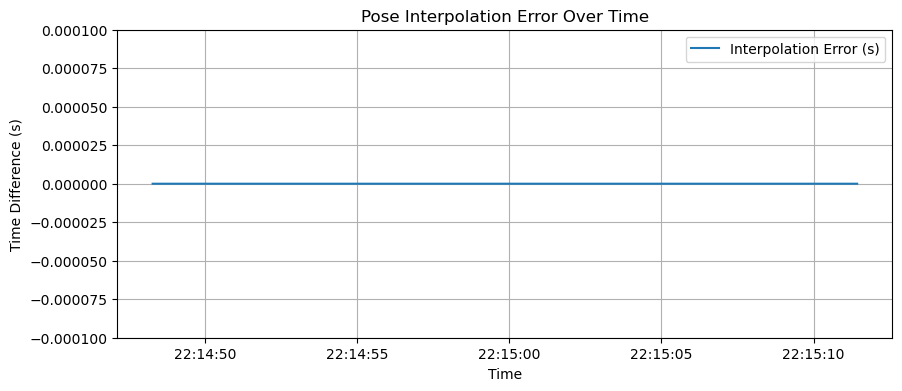

In [ ]:
time_diff = (interpolated_poses.index - vicon_twists.index).total_seconds()
plt.figure(figsize=(10, 4))
plt.plot(vicon_twists.index, time_diff, label="Interpolation Error (s)")
plt.ylim(-.0001,0.0001)
plt.xlabel("Time")
plt.ylabel("Time Difference (s)")
plt.title("Pose Interpolation Error Over Time")
plt.legend()
plt.grid(True)
plt.show()


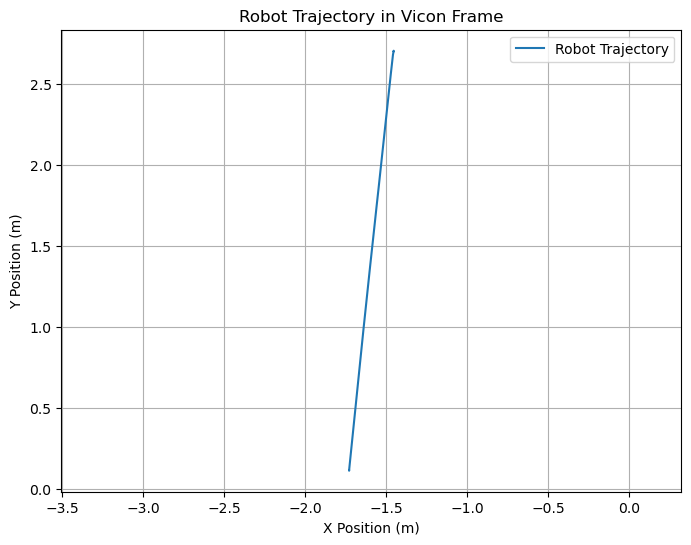

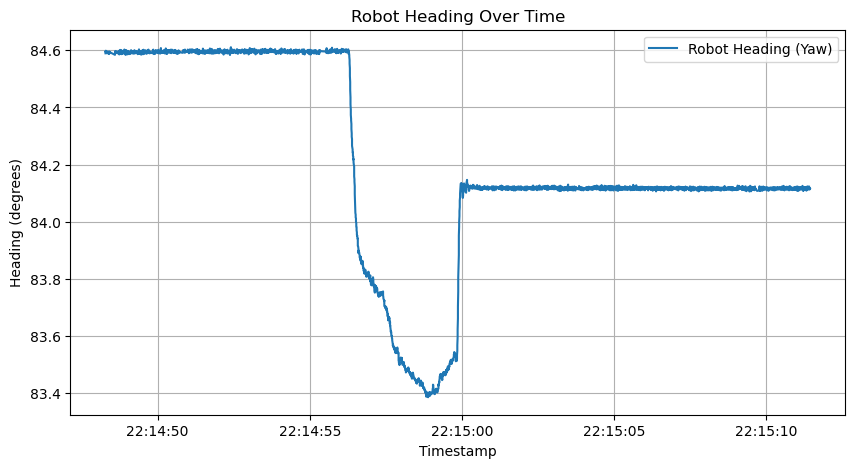

In [ ]:
# Plot X and Y position of the robot in the Vicon frame
plt.figure(figsize=(8, 6))
plt.plot(vicon_poses["pose.position.x"], vicon_poses["pose.position.y"], label="Robot Trajectory")
plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("Robot Trajectory in Vicon Frame")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

# Compute heading from quaternion (yaw angle)
import numpy as np
from scipy.spatial.transform import Rotation as R

yaw_angles = R.from_quat(
    np.column_stack([
        vicon_poses["pose.orientation.x"],
        vicon_poses["pose.orientation.y"],
        vicon_poses["pose.orientation.z"],
        vicon_poses["pose.orientation.w"]
    ])
).as_euler('zyx')[:, 0]  # Extract yaw (heading) component

# Plot heading over time
plt.figure(figsize=(10, 5))
plt.plot(vicon_poses.index, np.degrees(yaw_angles), label="Robot Heading (Yaw)")
plt.xlabel("Timestamp")
plt.ylabel("Heading (degrees)")
plt.title("Robot Heading Over Time")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
from scipy.signal import savgol_filter


def savgol_derivative(data: NDArray, time: NDArray, window_size=21, poly_order=3):
    """
    Compute the numerical derivative using Savitzky-Golay filtering.

    Parameters:
        data (NDArray): (D, N) position or quaternion data.
        time (NDArray): (N,) time vector.
        window_size (int): Filter window size (must be odd).
        poly_order (int): Polynomial order (should be < window_size).

    Returns:
        NDArray: (D, N) filtered derivative (velocity or angular velocity).
    """
    # TODO See how much using a single mean dt value affects accuracy.
    # TODO Would it be better to interp to an evenly spaced dt grid?
    dt = np.mean(
        np.diff(time), axis=0
    )  # Average timestep to avoid noise from small dt variations

    return savgol_filter(
        data, window_length=window_size, polyorder=poly_order, deriv=1, delta=dt, axis=1
    )


def quaternion_derivative_savgol(
    quats: NDArray, time: NDArray, window_size=21, poly_order=3
) -> NDArray:
    """
    Compute the angular velocity from a sequence of quaternions using Savitzky-Golay filtering.

    Parameters:
        quats (NDArray): (4, N) array of quaternions (qx, qy, qz, qw) at each time step.
        time (NDArray): (N,) array of time values corresponding to each quaternion.
        window_size (int): The window length for Savitzky-Golay filtering (must be odd).
        poly_order (int): Polynomial order for Savitzky-Golay filtering.

    Returns:
        NDArray: (3, N) array of angular velocities (wx, wy, wz) in rad/s.
        NDArray: (7, N) array of angular velocities (qx,qy,qz,qw, wx, wy, wz) in rad/s.
    """
    quats = quats.T  # Convert from (4, N) to (N, 4) for scipy.
    print(quats.shape)
    rotations = R.from_quat(quats)

    # Convert quaternion differences to rotation vectors
    rotvecs = np.zeros((len(time), 3))  # (N, 3)
    rotvecs[1:] = (rotations[:-1].inv() * rotations[1:]).as_rotvec()

    # TODO make this not a single scalar constant?
    dt = np.mean(np.diff(time), axis=0)

    # TODO Find optimal way to tune polyorder and window size params to avoid over smoothing/fitting.
    ang_vels = savgol_filter(
        rotvecs.T,
        window_length=window_size,
        polyorder=poly_order,
        deriv=1,
        delta=dt,
        axis=1,
    )

    # Turn euler back to quat?
    quat_vels = R.from_euler("xyz", ang_vels.T).as_quat()
    print("Qual vels", quat_vels.shape)

    ang_vels = np.vstack([ang_vels, quat_vels.T])
    print("Final angles shape", ang_vels.shape)

    return ang_vels  # (7, N)


(4548, 4)
Qual vels (4548, 4)
Final angles shape (7, 4548)


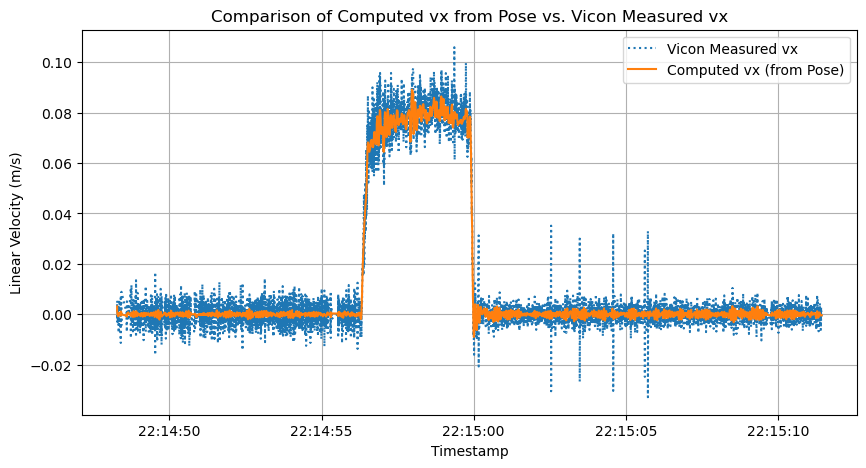

In [ ]:
import numpy as np
import pandas as pd
import PyKDL
from scipy.spatial.transform import Rotation as R
from scipy.signal import savgol_filter
from geometry_msgs.msg import TwistStamped


def compute_twist_from_pose(
    vicon_poses: pd.DataFrame, window_size=21, poly_order=3
) -> pd.DataFrame:
    """
    Compute a TwistStamped-equivalent DataFrame from a PoseStamped DataFrame.

    :param vicon_poses: DataFrame containing ['pose.position.x', 'pose.position.y', 'pose.position.z',
                                              'pose.orientation.x', 'pose.orientation.y', 'pose.orientation.z', 'pose.orientation.w']
    :param window_size: Window size for Savitzky-Golay smoothing.
    :param poly_order: Polynomial order for Savitzky-Golay smoothing.
    :return: DataFrame with ['twist.linear.x', 'twist.linear.y', 'twist.linear.z',
                             'twist.angular.x', 'twist.angular.y', 'twist.angular.z']
    """
    # Ensure timestamps are numerical
    time = vicon_poses.index.view(np.int64) / 1e9  # Convert from nanoseconds to seconds

    # Extract linear position
    positions = vicon_poses[
        ["pose.position.x", "pose.position.y", "pose.position.z"]
    ].values.T  # (3, N)

    # Compute linear velocity
    linear_velocity = savgol_derivative(positions, time, window_size, poly_order)

    # Extract quaternion orientation
    quaternions = vicon_poses[
        [
            "pose.orientation.x",
            "pose.orientation.y",
            "pose.orientation.z",
            "pose.orientation.w",
        ]
    ].values.T  # (4, N)

    # Compute angular velocity
    angular_velocity = quaternion_derivative_savgol(
        quaternions, time, window_size, poly_order
    )[:3]  # Take only (wx, wy, wz)

    # Create DataFrame for TwistStamped
    twist_df = pd.DataFrame(
        {
            "twist.linear.x": linear_velocity[0],
            "twist.linear.y": linear_velocity[1],
            "twist.linear.z": linear_velocity[2],
            "twist.angular.x": angular_velocity[0],
            "twist.angular.y": angular_velocity[1],
            "twist.angular.z": angular_velocity[2],
        },
        index=vicon_poses.index,
    )

    twist_df.index.name = "timestamp"

    return twist_df


# Compute twist from vicon pose
computed_twists = compute_twist_from_pose(vicon_poses)

# Plot results
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(
    vicon_twists.index,
    vicon_twists["twist.linear.x"],
    label="Vicon Measured vx",
    linestyle="dotted",
)
plt.plot(
    computed_twists.index,
    computed_twists["twist.linear.x"],
    label="Computed vx (from Pose)",
    linestyle="-",
)
plt.xlabel("Timestamp")
plt.ylabel("Linear Velocity (m/s)")
plt.title("Comparison of Computed vx from Pose vs. Vicon Measured vx")
plt.legend()
plt.grid(True)
plt.show()


NaNs in Computed Twists:
twist.linear.x     0
twist.linear.y     0
twist.linear.z     0
twist.angular.x    0
twist.angular.y    0
twist.angular.z    0
dtype: int64

NaNs in Vicon Twists:
header.stamp.sec        0
header.stamp.nanosec    0
header._frame_id        0
twist.linear.x          0
twist.linear.y          0
twist.linear.z          0
twist.angular.x         0
twist.angular.y         0
twist.angular.z         0
dtype: int64
Computed Twists Index Range: 2025-02-16 22:14:48.284613132 to 2025-02-16 22:15:11.434619188
Vicon Twists Index Range: 2025-02-16 22:14:48.284707785 to 2025-02-16 22:15:11.434724092

Intersection of Indices: 0
Total Computed Twists Samples: 4548
Total Vicon Twists Samples: 4548
Velocity Error Metrics (Computed - Measured):
vx: Mean = -0.00022, Std = 0.00432
vy: Mean = -0.00205, Std = 0.01118
vz: Mean = 0.00005, Std = 0.01607


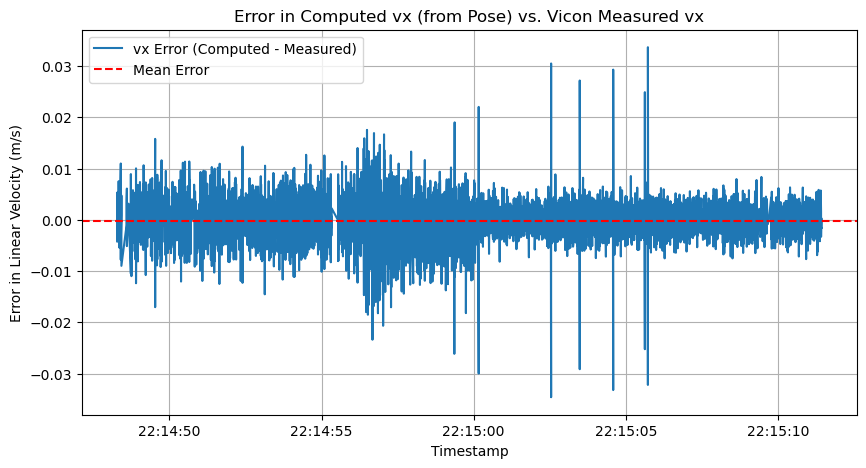

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("NaNs in Computed Twists:")
print(computed_twists.isna().sum())

print("\nNaNs in Vicon Twists:")
print(vicon_twists.isna().sum())

print("Computed Twists Index Range:", computed_twists.index.min(), "to", computed_twists.index.max())
print("Vicon Twists Index Range:", vicon_twists.index.min(), "to", vicon_twists.index.max())

print("\nIntersection of Indices:", computed_twists.index.intersection(vicon_twists.index).shape[0])
print("Total Computed Twists Samples:", computed_twists.shape[0])
print("Total Vicon Twists Samples:", vicon_twists.shape[0])

aligned_computed = computed_twists.reindex(vicon_twists.index, method='nearest')
# vx_error = aligned_computed["twist.linear.x"] - vicon_twists["twist.linear.x"]


# Compute errors
vx_error = aligned_computed["twist.linear.x"] - vicon_twists["twist.linear.x"]
vy_error = aligned_computed["twist.linear.y"] - vicon_twists["twist.linear.y"]
vz_error = aligned_computed["twist.linear.z"] - vicon_twists["twist.linear.z"]

# Compute mean and standard deviation of errors
error_metrics = {
    "vx": {"mean": vx_error.mean(), "std": vx_error.std()},
    "vy": {"mean": vy_error.mean(), "std": vy_error.std()},
    "vz": {"mean": vz_error.mean(), "std": vz_error.std()},
}

print("Velocity Error Metrics (Computed - Measured):")
for axis, metrics in error_metrics.items():
    print(f"{axis}: Mean = {metrics['mean']:.5f}, Std = {metrics['std']:.5f}")

# Plot error over time
plt.figure(figsize=(10, 5))
plt.plot(vx_error.index, vx_error, label="vx Error (Computed - Measured)", linestyle="-")
plt.axhline(y=vx_error.mean(), color="r", linestyle="--", label="Mean Error")
plt.xlabel("Timestamp")
plt.ylabel("Error in Linear Velocity (m/s)")
plt.title("Error in Computed vx (from Pose) vs. Vicon Measured vx")
plt.legend()
plt.grid(True)
plt.show()


In [2]:
from geometry_msgs.msg import Point, Quaternion

""" How to apply transforms to the data? Should I do it here why It's in the ros2 data forms? Should I convert them to data 
frames and write a wrapper func to convert the pose there? That would require a wrapper that can handle different representations of the data.
Let's use the tf stuff alread made for us.
"""
# geometry_msgs.msg.TwistStamped(header=std_msgs.msg.Header(
#   stamp=builtin_interfaces.msg.Time(sec=1739744088, nanosec=284786535), frame_id='vicon'),
#   twist=geometry_msgs.msg.Twist(
#       linear=geometry_msgs.msg.Vector3(x=0.4254357674833287, y=-0.6499396153401449, z=0.40347531183193563),
#       angular=geometry_msgs.msg.Vector3(x=-0.3853726058453176, y=-0.6616056789418917, z=-0.4909611057338067))),1739744088284804517),

# Let's try tranforming vicon TwistStamped messages from the vicon frame into the base_link odom frame.
tf_static_msgs = msgs["/tf_static"]

vicon_pose = msgs["/vrpn_mocap/rb1/twist"][100]
print(type(vicon_pose))  # PoseStamped

# Make a TF buffer and populate with static xforms.
tf_buffer = tf2_ros.Buffer()
for tf_msg in tf_static_msgs:
    for transform in tf_msg.transforms:
        # print(transform)
        tf_buffer.set_transform(transform, "default_authority")

# Fake test message
pose_msg = PoseStamped()
pose_msg.header.frame_id = "vicon"
pose_msg.pose.position = Point(
    x=0,
    y=0,
    z=0,
)
pose_msg.pose.orientation = Quaternion(
    x=0,
    y=0,
    z=0,
    w=1,
)


# Apply the transformation
try:
    # Target, Source
    transform = tf_buffer.lookup_transform("vicon", "base_link", rclpy.time.Time())
    transformed_pose = tf2_geometry_msgs.do_transform_pose_stamped(pose_msg, transform)
    print("Transformed Twist:", transformed_pose)
except tf2_ros.LookupException:
    print("Transform lookup failed!")


NameError: name 'msgs' is not defined

In [ ]:
from viz_utils import publish_pose_stamped, send_transform, send_static_transform

static_xforms = msgs["/tf_static"][0].transforms

send_static_transform(static_xforms)
publish_pose_stamped([transformed_pose])


[WARN] [1741543639.908328189] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1741543639.908335730] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.
[WARN] [1741543642.058290708] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1741543642.058302446] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.


In [ ]:
# """ Plot the TF frames in 3D space. To do this we would have to traverse the tf2 hierarchy
# and apply transforms though.
# """

# r = R.from_quat(quaternions)
# rpy = r.as_euler('xyz', degrees=True)  # Convert to RPY (degrees)

# # 3D plot setup
# fig = plt.figure(figsize=(6, 6))
# ax = fig.add_subplot(111, projection='3d')

# # Coordinate frame
# ax.quiver(0, 0, 0, 1, 0, 0, color='r', label="Roll (X-axis)")
# ax.quiver(0, 0, 0, 0, 1, 0, color='g', label="Pitch (Y-axis)")
# ax.quiver(0, 0, 0, 0, 0, 1, color='b', label="Yaw (Z-axis)")

# ax.set_xlim([-1, 1])
# ax.set_ylim([-1, 1])
# ax.set_zlim([-1, 1])
# ax.set_xlabel("X")
# ax.set_ylabel("Y")
# ax.set_zlabel("Z")
# plt.legend()
# plt.title("Roll-Pitch-Yaw Vectors")
# plt.show()